<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session12_dimensionality_reduction_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۱۲: کاهش ابعاد (Dimensionality Reduction)

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session12_dimensionality_reduction.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
import seaborn as sns

sns.set_theme(style="whitegrid")

digits = load_digits()
X_digits, y_digits = digits.data, digits.target

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

PCA را روی دادهٔ سرطان سینه (۳۰ ویژگی) اجرا کنید. چند مؤلفه ۹۵٪ واریانس را حفظ می‌کند؟ داده را در دو بعد اول رسم کنید.

</div>

Components needed for 95% of the variance: 10 of 30


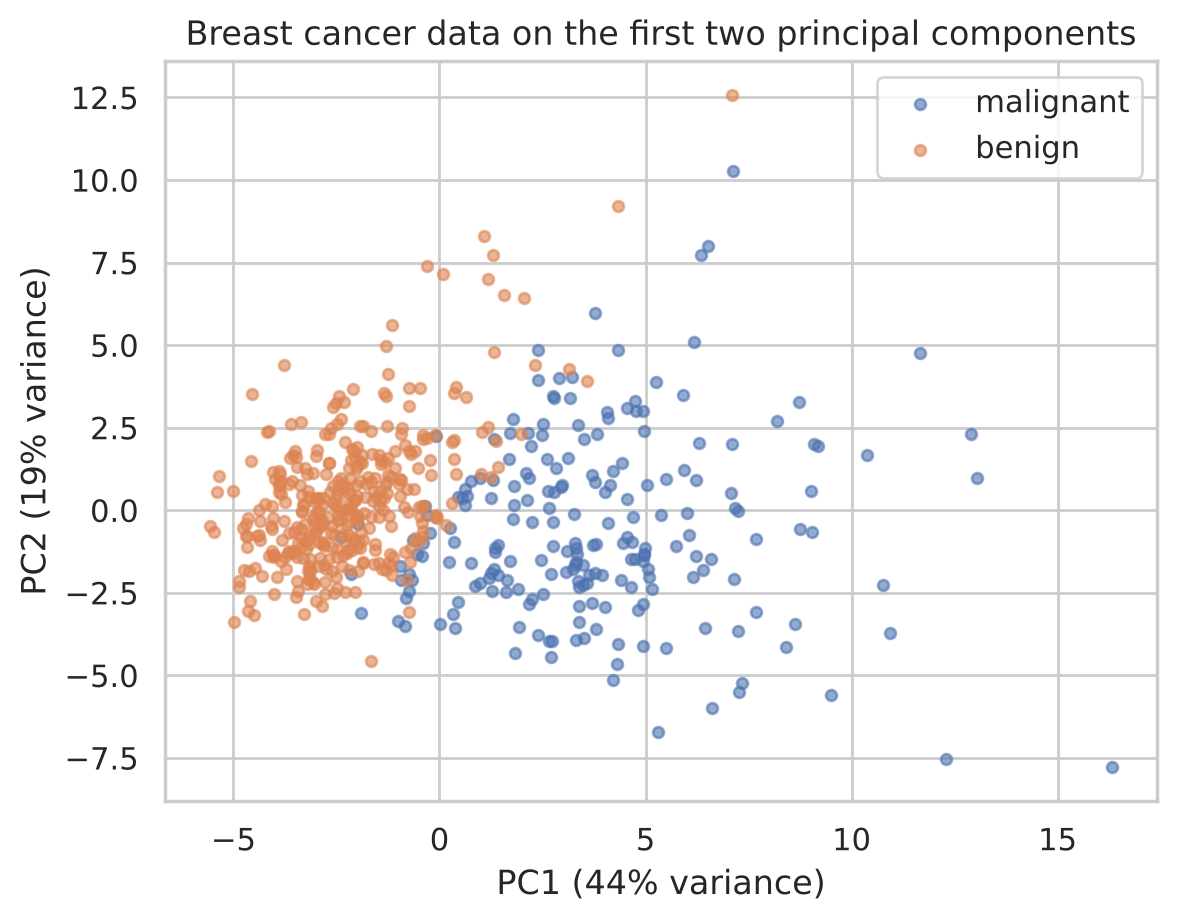

In [2]:
cancer = load_breast_cancer()
X_cancer = StandardScaler().fit_transform(cancer.data)
pca = PCA().fit(X_cancer)
n95 = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95)) + 1
print(f"Components needed for 95% of the variance: {n95} of 30")

Z = PCA(n_components=2).fit_transform(X_cancer)
for cls, name in enumerate(cancer.target_names):
    plt.scatter(Z[cancer.target == cls, 0], Z[cancer.target == cls, 1], label=name, alpha=0.6, s=15)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
plt.legend()
plt.title("Breast cancer data on the first two principal components")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با ۳۰ ویژگی، فقط حدود ۱۰ مؤلفه ۹۵٪ واریانس را حفظ می‌کنند؛ یعنی بسیاری از ویژگی‌ها اطلاعات تکراری دارند (مثلاً شعاع، محیط و مساحت هسته عملاً یک چیز را اندازه می‌گیرند). در دو بعد اول، تومورهای خوش‌خیم و بدخیم تقریباً جدا شده‌اند، با کمی هم‌پوشانی در مرز؛ به همین دلیل یک مدل خطی ساده روی این داده دقت بالایی دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

در Pipeline ارقام، `LogisticRegression` را با `KNeighborsClassifier` عوض کنید. PCA برای k-NN مفیدتر است یا برای رگرسیون لجستیک؟ چرا؟

</div>

In [3]:
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_digits, y_digits, test_size=0.25,
                                                        stratify=y_digits, random_state=42)
rows = []
for name, clf in [("LogisticRegression", LogisticRegression(max_iter=2000)),
                  ("KNeighborsClassifier", KNeighborsClassifier())]:
    pipe = Pipeline([("scale", StandardScaler()), ("pca", PCA()), ("clf", clf)])
    grid = GridSearchCV(pipe, {"pca__n_components": [5, 10, 20, 30, 40, 64]}, cv=5, n_jobs=-1)
    grid.fit(Xd_train, yd_train)
    for n, score in zip(grid.cv_results_["param_pca__n_components"], grid.cv_results_["mean_test_score"]):
        rows.append({"classifier": name, "components": n, "CV accuracy": score})
pd.DataFrame(rows).pivot(index="components", columns="classifier", values="CV accuracy").round(3)

classifier,KNeighborsClassifier,LogisticRegression
components,,
5,0.876,0.823
10,0.930,0.883
20,0.968,0.950
30,0.976,0.962
40,0.974,0.966
64,0.977,0.970


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در هر دو مدل، دقت با تعداد مؤلفه‌ها بالا می‌رود. ولی k-NN خیلی زودتر به سقف می‌رسد: با ۳۰ مؤلفه (کمتر از نصف ابعاد) دقتش عملاً همان دقت با ۶۴ ویژگی است و در هر تعداد مؤلفه از رگرسیون لجستیک بهتر است. پس PCA برای k-NN مفیدتر است: با حدود نصف ابعاد، همان دقت را می‌دهد و چون k-NN برای هر پیش‌بینی فاصله تا همهٔ نمونه‌ها را حساب می‌کند، پیش‌بینی هم سریع‌تر می‌شود. مؤلفه‌های کم‌واریانس عمدتاً نویزند و برای مدلی که بر پایهٔ **فاصله** کار می‌کند، اطلاعات مفیدی ندارند (نفرین ابعاد، جلسهٔ ۶).

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

t-SNE را با `perplexity` برابر ۵، ۳۰ و ۱۰۰ روی ارقام اجرا کنید و نتایج را مقایسه کنید.

</div>

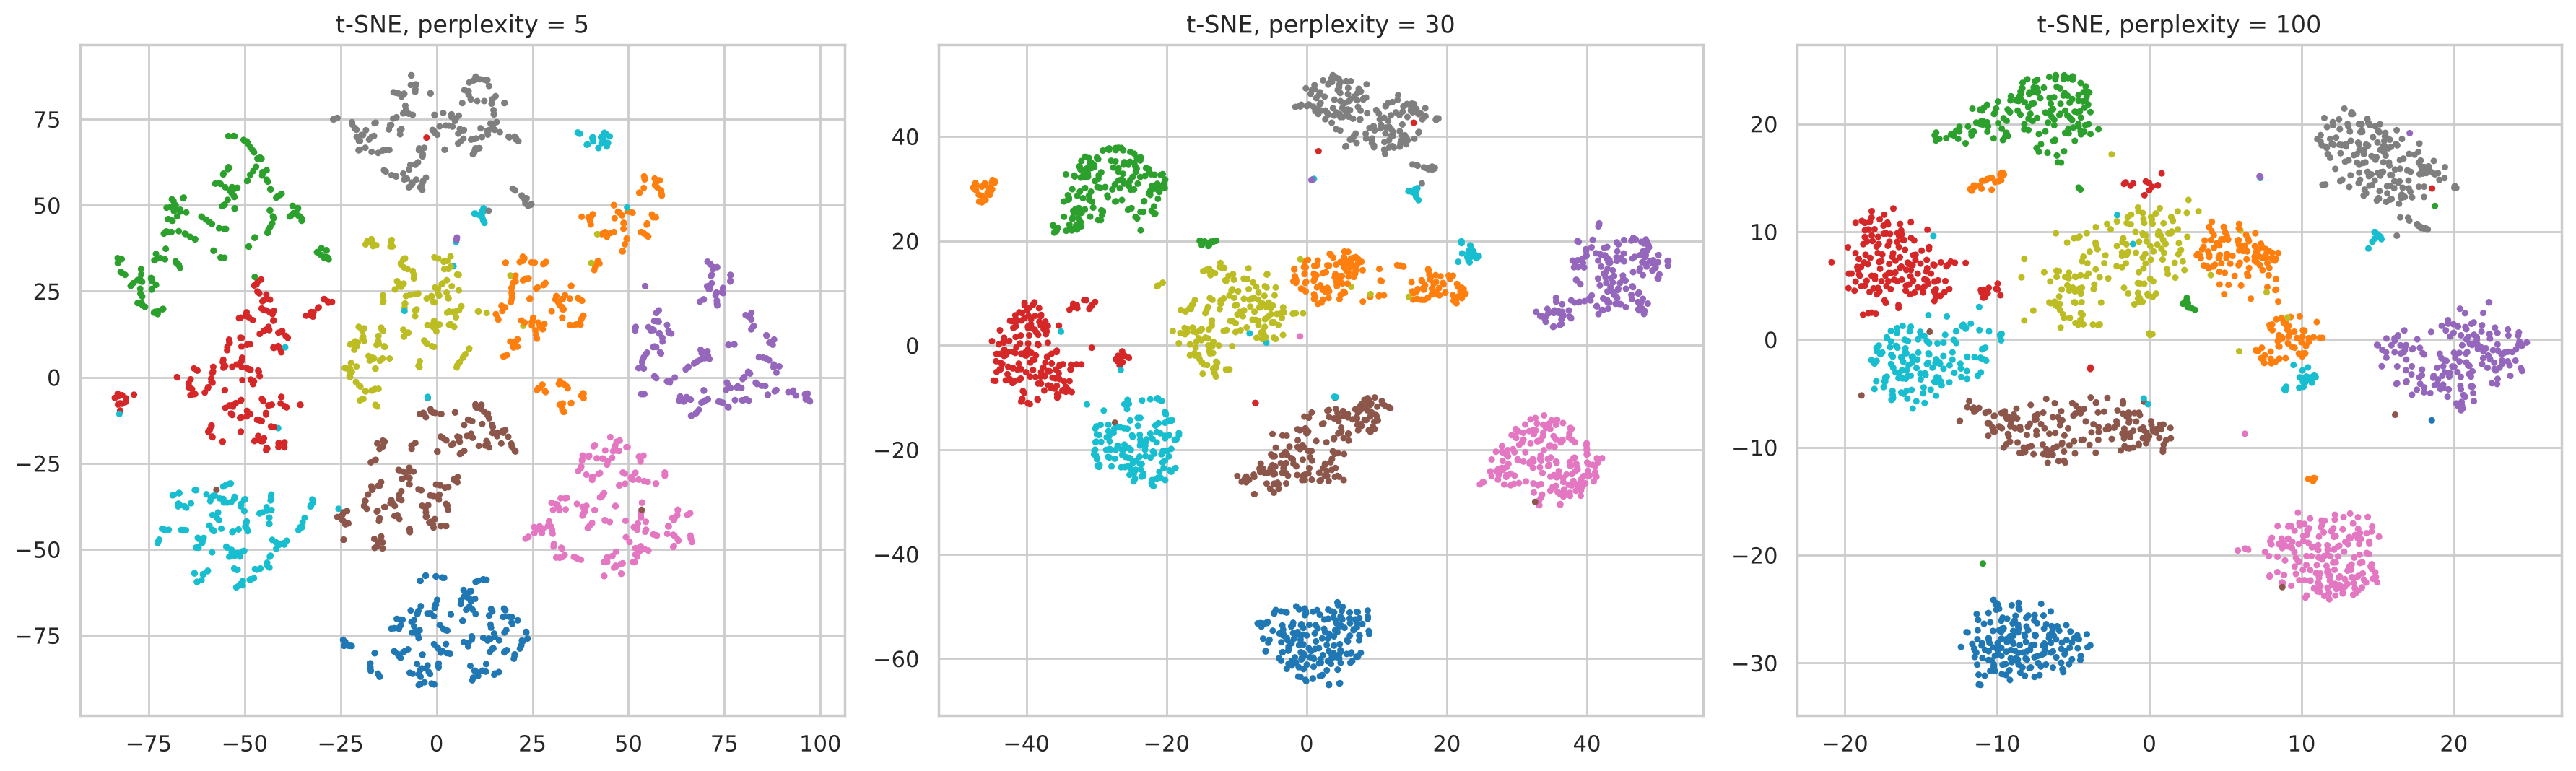

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, perplexity in zip(axes, [5, 30, 100]):
    Z = TSNE(n_components=2, perplexity=perplexity, random_state=42).fit_transform(X_digits)
    ax.scatter(Z[:, 0], Z[:, 1], c=y_digits, cmap="tab10", s=5)
    ax.set_title(f"t-SNE, perplexity = {perplexity}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- **perplexity کوچک (۵):** فقط همسایه‌های بسیار نزدیک در نظر گرفته می‌شوند؛ خوشه‌ها به جزیره‌های کوچک‌تری تکه‌تکه می‌شوند.
- **perplexity متوسط (۳۰):** ده خوشهٔ واضح، یکی برای هر رقم.
- **perplexity بزرگ (۱۰۰):** ساختار کلی‌تر حفظ می‌شود و خوشه‌ها فشرده‌تر و نزدیک‌تر به هم دیده می‌شوند.

شکل نمودار با perplexity عوض می‌شود، ولی **همسایگی‌ها** (کدام ارقام کنار هم‌اند) تقریباً ثابت می‌ماند. به همین دلیل باید فقط ساختار محلی t-SNE را تفسیر کرد، نه اندازه یا فاصلهٔ خوشه‌ها را.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

تصاویر ارقام را با ۱۰ مؤلفهٔ PCA فشرده کنید و نسبت فشرده‌سازی و خطای بازسازی (MSE) را حساب کنید.

</div>

In [5]:
pca10 = PCA(n_components=10).fit(X_digits)
reconstructed = pca10.inverse_transform(pca10.transform(X_digits))
mse = np.mean((X_digits - reconstructed) ** 2)
stored = X_digits.shape[0] * 10 + pca10.components_.size + pca10.mean_.size
print(f"Original numbers stored:   {X_digits.size:,}")
print(f"Compressed numbers stored: {stored:,} (10 scores per image + components + mean)")
print(f"Compression ratio: {X_digits.size / stored:.1f}x")
print(f"Reconstruction MSE: {mse:.2f} (pixel values range from 0 to 16)")
print(f"Variance kept: {pca10.explained_variance_ratio_.sum():.1%}")

Original numbers stored:   115,008
Compressed numbers stored: 18,674 (10 scores per image + components + mean)
Compression ratio: 6.2x
Reconstruction MSE: 4.91 (pixel values range from 0 to 16)
Variance kept: 73.8%


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با ذخیرهٔ ۱۰ عدد به‌جای ۶۴ عدد برای هر تصویر (به‌علاوهٔ ماتریس مؤلفه‌ها و میانگین که فقط یک بار ذخیره می‌شوند)، حجم داده حدود ۶ برابر کم می‌شود. MSE حدود ۵ یعنی خطای متوسط هر پیکسل حدود ۲ واحد در بازهٔ ۰ تا ۱۶ است و حدود سه‌چهارم واریانس حفظ شده؛ همان‌طور که در جلسه دیدیم، ارقام بازسازی‌شده با ۱۰ مؤلفه کمی تار ولی کاملاً قابل تشخیص‌اند.

</div>